In [1]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt


training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

100%|████████████████████████████████████████████████████████████████| 26421880/26421880 [00:01<00:00, 18877341.58it/s]


Extracting data\FashionMNIST\raw\train-images-idx3-ubyte.gz to data\FashionMNIST\raw



100%|███████████████████████████████████████████████████████████████████████| 29515/29515 [00:00<00:00, 1540772.19it/s]

Extracting data\FashionMNIST\raw\train-labels-idx1-ubyte.gz to data\FashionMNIST\raw



100%|██████████████████████████████████████████████████████████████████| 4422102/4422102 [00:00<00:00, 16717206.32it/s]


Extracting data\FashionMNIST\raw\t10k-images-idx3-ubyte.gz to data\FashionMNIST\raw



100%|██████████████████████████████████████████████████████████████████████████████████████| 5148/5148 [00:00<?, ?it/s]

Extracting data\FashionMNIST\raw\t10k-labels-idx1-ubyte.gz to data\FashionMNIST\raw



In [7]:
training_data[100][0].shape

torch.Size([1, 28, 28])

In [9]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)

In [10]:
print(next(iter(train_dataloader)))

[tensor([[[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0039, 0.0000],
          ...,
          [0.0000, 0.1373, 0.3255,  ..., 0.7137, 0.8157, 0.0157],
          [0.0000, 0.0000, 0.0000,  ..., 0.5843, 0.5882, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],


        [[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]]],


        [[[0.0000, 0.0000, 0.0039,  ..., 0.0078, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0078,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0118,  .

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import torch
from torch import optim
from torch import nn
from torch.utils.data import DataLoader
from tqdm import tqdm

# !pip install torchvision
import torchvision

import torch.nn.functional as F
import torchvision.datasets as datasets
import torchvision.transforms as transforms

# !pip install torchmetrics
import torchmetrics

In [2]:
batch_size = 60

train_dataset = datasets.MNIST(root="dataset/", download=True, train=True, transform=transforms.ToTensor())

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = datasets.MNIST(root="dataset/", download=True, train=False, transform=transforms.ToTensor())

test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=True)

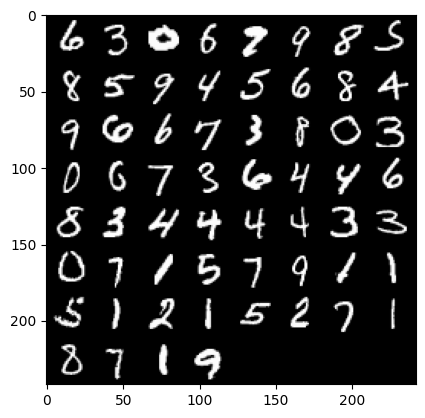

In [3]:
def imshow(img):
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# get some random training images
dataiter = iter(train_loader)
images, labels = next(dataiter)
labels
# show images
imshow(torchvision.utils.make_grid(images))


In [4]:
class CNN(nn.Module):
   def __init__(self, in_channels, num_classes):

       """
       Building blocks of convolutional neural network.

       Parameters:
           * in_channels: Number of channels in the input image (for grayscale images, 1)
           * num_classes: Number of classes to predict. In our problem, 10 (i.e digits from  0 to 9).
       """
       super(CNN, self).__init__()

       # 1st convolutional layer
       self.conv1 = nn.Conv2d(in_channels=in_channels, out_channels=8, kernel_size=3, padding=1)
       # Max pooling layer
       self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
       # 2nd convolutional layer
       self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, padding=1)
       # Fully connected layer
       self.fc1 = nn.Linear(16 * 7 * 7, num_classes)

   def forward(self, x):
       """
       Define the forward pass of the neural network.

       Parameters:
           x: Input tensor.

       Returns:
           torch.Tensor
               The output tensor after passing through the network.
       """
       x = F.relu(self.conv1(x))  # Apply first convolution and ReLU activation
       x = self.pool(x)           # Apply max pooling
       x = F.relu(self.conv2(x))  # Apply second convolution and ReLU activation
       x = self.pool(x)           # Apply max pooling
       x = x.reshape(x.shape[0], -1)  # Flatten the tensor
       x = self.fc1(x)            # Apply fully connected layer
       return x
       x = x.reshape(x.shape[0], -1)  # Flatten the tensor
       x = self.fc1(x)            # Apply fully connected layer
       return x

In [5]:
model = CNN(in_channels=1, num_classes=10)
print(model)

CNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=784, out_features=10, bias=True)
)


In [6]:
# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [8]:
num_epochs=10
for epoch in range(num_epochs):
 # Iterate over training batches
   print(f"Epoch [{epoch + 1}/{num_epochs}]")

   for batch_index, (data, targets) in enumerate(tqdm(train_loader)):
#     print(targets)
#        print(data.shape)
       scores = model(data)
       print('scores ', scores)
       print('scores ', np.sum(scores.detach().numpy(), axis=1))
       print('targets ', targets) 
       loss = criterion(scores, targets)
       optimizer.zero_grad()
       loss.backward()
       optimizer.step()

Epoch [1/10]


  0%|▏                                                                                | 3/1000 [00:00<00:34, 28.65it/s]

scores  tensor([[ -2.3049,  -1.9051,  -3.3750,  -2.8888,  -2.3887,   1.9897,  -1.4468,
          -5.8508,  -1.3314,  -3.7221],
        [ -2.7516,  -5.2261,  -6.5986,   0.7146,  -5.7626,   4.1360,  -8.3331,
          -7.1074,  -1.2000,  -4.7443],
        [  2.3257,  -8.4948,  -4.6004,  -1.2063,  -4.8882,  -1.6077,  -5.1159,
          -3.4207,  -0.4868,  -1.5535],
        [ -4.5983,  -5.2887,  -1.4710,  -2.2172,  -0.2011,  -2.9092,   2.4192,
          -6.6831,  -0.6792,  -2.9047],
        [ -4.6802,   4.1421,  -1.8343,  -0.9020,  -2.0981,  -1.2672,  -2.7127,
          -1.2912,  -1.1302,  -1.0289],
        [ -4.3049,  -4.1293,  -0.3242,   2.9419,  -7.4609,  -1.9379,  -6.9522,
          -7.3341,   0.6022,  -4.5996],
        [ -3.2774,  -4.8024,  -3.4356,  -2.8240,   0.8785,  -2.9464,  -3.5450,
          -2.7938,  -1.0442,   1.3791],
        [ -6.1761,  -7.9850,   1.9086,  -1.7616,  -1.8438,   0.7366,   1.5285,
         -10.6482,  -2.1959,  -7.1643],
        [ -4.6362,  -8.1875,  -1.3457,  

scores  tensor([[-3.9932e+00, -3.6662e+00, -5.8098e+00, -1.8628e+00, -4.1870e+00,
          3.3585e+00, -4.5547e+00, -4.5256e+00,  9.4377e-01, -2.4808e+00],
        [-2.2949e+00, -9.0312e+00, -2.1185e+00, -4.2627e+00, -2.8174e+00,
         -2.0741e+00, -4.7850e+00, -3.4814e+00,  1.4357e+00, -1.4240e+00],
        [-4.2572e+00, -5.6548e+00, -3.8894e+00,  3.5072e+00, -6.4765e+00,
          6.9064e-01, -7.7091e+00, -4.2427e-01, -5.1913e-02, -1.6286e+00],
        [-2.5338e+00, -1.5280e+01, -7.7767e+00, -5.4698e-01, -7.8599e+00,
         -4.2262e+00, -1.3449e+01,  9.4878e+00, -2.4519e+00,  5.4212e-01],
        [-7.4453e+00, -1.1180e+01,  7.5889e+00, -4.8179e-01, -1.0641e+01,
         -4.6208e+00, -5.6786e+00, -9.0114e+00,  6.2915e-01, -8.4064e+00],
        [-3.9737e+00, -1.4063e+01, -8.5421e-01, -5.3362e+00,  3.3549e-01,
         -4.8895e+00,  3.3210e+00, -5.2171e+00, -2.4261e+00, -4.5967e+00],
        [-9.0207e-01, -5.8191e+00, -4.0916e+00, -4.5448e+00, -3.9647e+00,
          2.9041e+00, -3

  1%|▌                                                                                | 7/1000 [00:00<00:32, 30.35it/s]

...

scores  tensor([[-5.5501e+00, -1.2595e+01, -4.0115e+00, -9.3448e-01, -1.5496e+01,
          9.7007e+00, -1.1753e+01, -7.3626e+00,  3.2003e-01, -4.4120e+00],
        [-2.5713e+00,  2.5057e-01,  8.2922e+00, -7.1998e-01, -1.3887e+01,
         -5.4569e+00, -5.6867e+00, -1.3097e+01, -8.5120e-02, -1.0323e+01],
        [-9.2088e+00, -1.0850e+01, -5.8486e+00, -1.9927e+00, -4.2528e+00,
          8.0755e-01, -1.1775e+01,  2.0301e-02, -5.2750e-01,  4.8477e+00],
        [-3.7477e+00, -2.6616e+00,  9.3651e-01, -6.7910e-01, -1.0118e+01,
         -6.2248e+00, -1.4954e+01,  5.1715e+00, -3.0975e+00,  1.3220e+00],
        [ 6.2275e+00, -1.4711e+01, -2.0938e+00, -4.9580e+00, -7.6961e+00,
         -1.1061e+00, -3.9671e+00, -2.8240e+00, -1.6690e-01, -1.5640e+00],
        [-5.9152e+00, -1.0413e+01, -1.7121e+00,  2.5917e+00, -1.3234e+01,
         -6.7238e+00, -2.0815e+01,  1.3015e+01, -6.8026e+00,  1.0628e+00],
        [-3.3410e+00, -9.0502e+00, -2.1038e+00,  2.9662e+00, -9.0329e+00,
         -9.5072e-01, -1

 71%|████████████████████████████████████████████████████████▏                      | 711/1000 [00:31<00:13, 22.07it/s]

scores  tensor([[-1.2775e+01, -7.8176e+00,  1.1860e+00,  2.5670e+00, -6.3118e+00,
         -5.6891e+00, -1.5065e+01,  4.7392e+00, -2.0281e+00,  6.1002e-01],
        [-4.5392e+00,  3.8682e+00,  1.6118e-02, -3.5678e+00, -2.7110e+00,
         -5.7191e+00, -2.9480e+00, -4.6640e+00, -5.2852e-01, -5.9493e+00],
        [-8.8442e+00, -5.5350e+00, -7.7366e+00, -1.6193e+00,  4.4916e-01,
         -1.6831e+00, -1.2925e+01,  3.6428e+00, -2.8475e+00,  6.1942e+00],
        [-3.6232e+00, -7.0039e+00,  5.7002e+00,  2.8623e+00, -1.4567e+01,
         -5.6944e+00, -1.0595e+01,  6.6256e+00, -8.7544e+00, -5.7953e+00],
        [-3.4109e+00,  4.9412e+00, -2.1610e-01, -2.7669e+00, -2.9862e+00,
         -5.9154e+00, -1.3036e+00, -4.3633e+00, -1.1507e+00, -3.9313e+00],
        [-4.4543e+00, -6.0354e+00,  1.5171e+00,  2.0624e+00, -1.0234e+01,
         -4.2838e+00, -6.2743e+00, -8.5203e+00,  3.1254e+00, -2.9993e+00],
        [-4.7783e+00, -9.1964e+00, -2.3064e+00, -3.1878e+00, -3.6162e+00,
         -8.7428e+00, -5

 71%|████████████████████████████████████████████████████████▏                      | 712/1000 [00:31<00:12, 22.88it/s]


KeyboardInterrupt: 